Project Introductio

Logistic Regression

N chandithya

medical dataset : heart csv

https://drive.google.com/file/d/1fY6P1frZabK5dKMHRGENGepBj0dEVeKN/view?usp=drive_link

The above dataset is about Heart disease like age ,heart disease , sex ,cholestral

The main goal of this project is to analyze,understand,visualize and clean datset like missing , duplicated, extra spaces values etc the main aspect of this analysis is to have clean and clear dataset and do the linear regression and logistic regression

In [34]:
#Importing the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

In [35]:
# Choose the used-cars CSV file from your computer
from google.colab import files
uploaded = files.upload()
csv_file = next(iter(uploaded))
df = pd.read_csv(csv_file)
print('Shape:', df.shape)
df.head()

Saving heart.csv to heart (1).csv
Shape: (918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [36]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [37]:
#checking for the missing values
df.isnull().sum()

,0
Age,0
Sex,0
ChestPainType,0
RestingBP,0
Cholesterol,0
FastingBS,0
RestingECG,0
MaxHR,0
ExerciseAngina,0
Oldpeak,0


In [38]:
#checking for the duplicated values
df.duplicated().sum()

np.int64(0)

In [39]:
# Univariate analysis
print(df["HeartDisease"].value_counts(normalize = True)*100)

HeartDisease
1    55.337691
0    44.662309
Name: proportion, dtype: float64


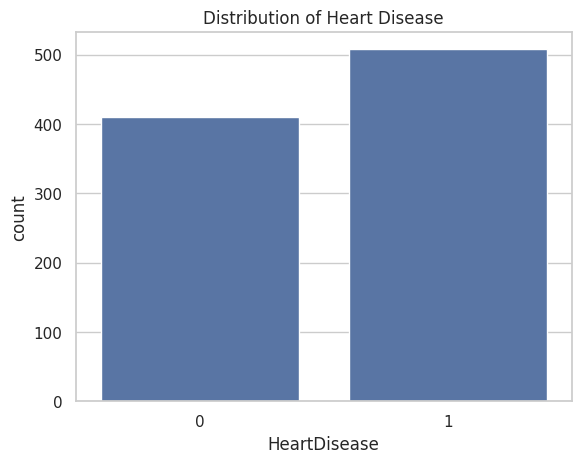

In [40]:
sns.countplot(data = df, x = "HeartDisease")
plt.title("Distribution of Heart Disease")
plt.show()

From the above distribution weobserve that we have almost 55% of people with heart disease therefore there are more with heart disease compared to those who dont have .

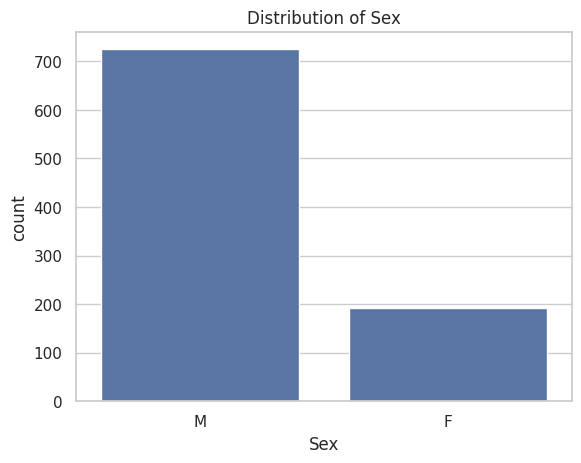

In [41]:
sns.countplot(data = df, x= "Sex")
plt.title("Distribution of Sex")
plt.show()

From the above distribution we can understand that there are more males who got checked for the heart disease

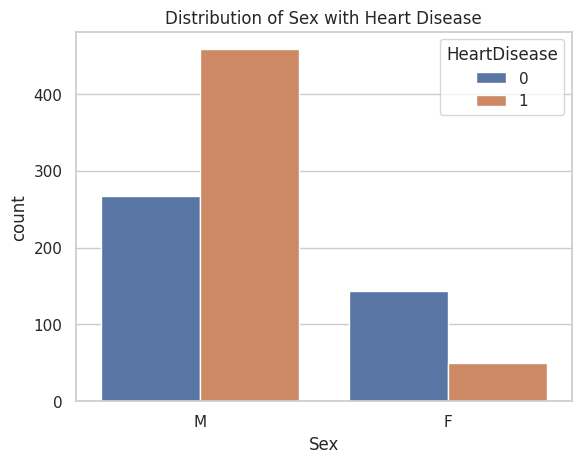

In [42]:
#Bivariate analysis
sns.countplot(data = df, x = "Sex", hue = "HeartDisease")
plt.title("Distribution of Sex with Heart Disease")
plt.show()

From the above bivariate distribution we can underestand that there are more male patient with gearrt disease compared female

*   Also we can see that more males are with heart disease out of all males tested
*   Whereas less females are with heart disease out all females tested



In [43]:
print(df["ChestPainType"].value_counts(normalize = True)*100)

ChestPainType
ASY    54.030501
NAP    22.113290
ATA    18.845316
TA      5.010893
Name: proportion, dtype: float64


In [44]:
numeric_df = df.select_dtypes(include = ["int64","float64"]).columns

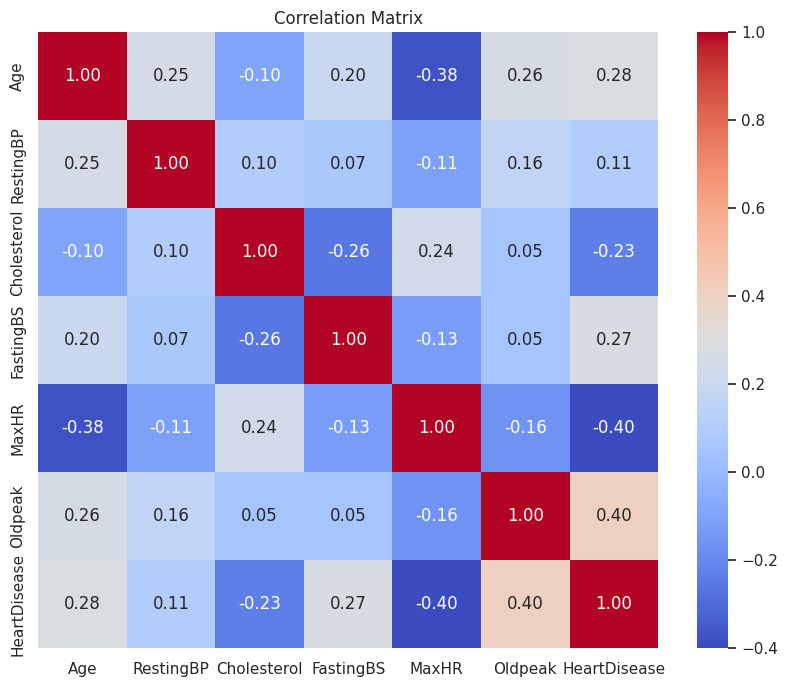

In [45]:
# Multivariate Analysis
plt.figure(figsize = (10, 8))
sns.heatmap(df[numeric_df].corr(), annot = True, cmap = "coolwarm",fmt= ".2f")
plt.title("Correlation Matrix")
plt.show()

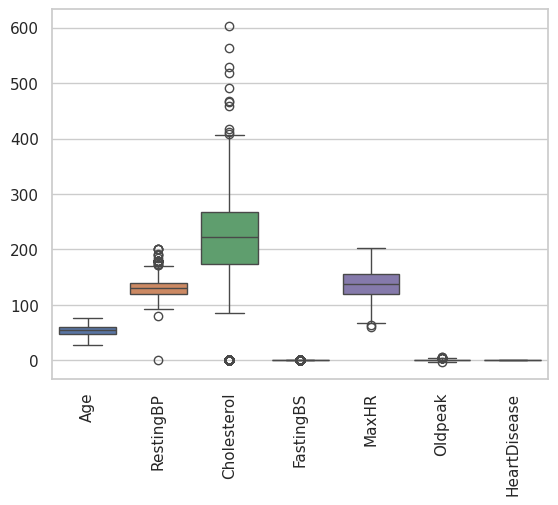

In [46]:
# Outlier detection
sns.boxplot(data =df[numeric_df])
plt.xticks(rotation = 90)
plt.show()

In [47]:
# Treating outliers
outlier_cols = [
    "RestingBP",
    "Cholesterol",
    "FastingBS",
    "MaxHR",
    "Oldpeak"
]

In [48]:
# Apply the IQR
for col in outlier_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3-Q1
    lower_bound = Q1 - 1.5*IQR
    upper_bound = Q3 + 1.5*IQR

    # cap values
    df[col] = np.where(df[col] < lower_bound, lower_bound, df[col])
    df[col] = np.where(df[col] > upper_bound, upper_bound, df[col])

So  from the above graph we have seen outliers in the above outliers columns and we treated them using upper bound and lower bound

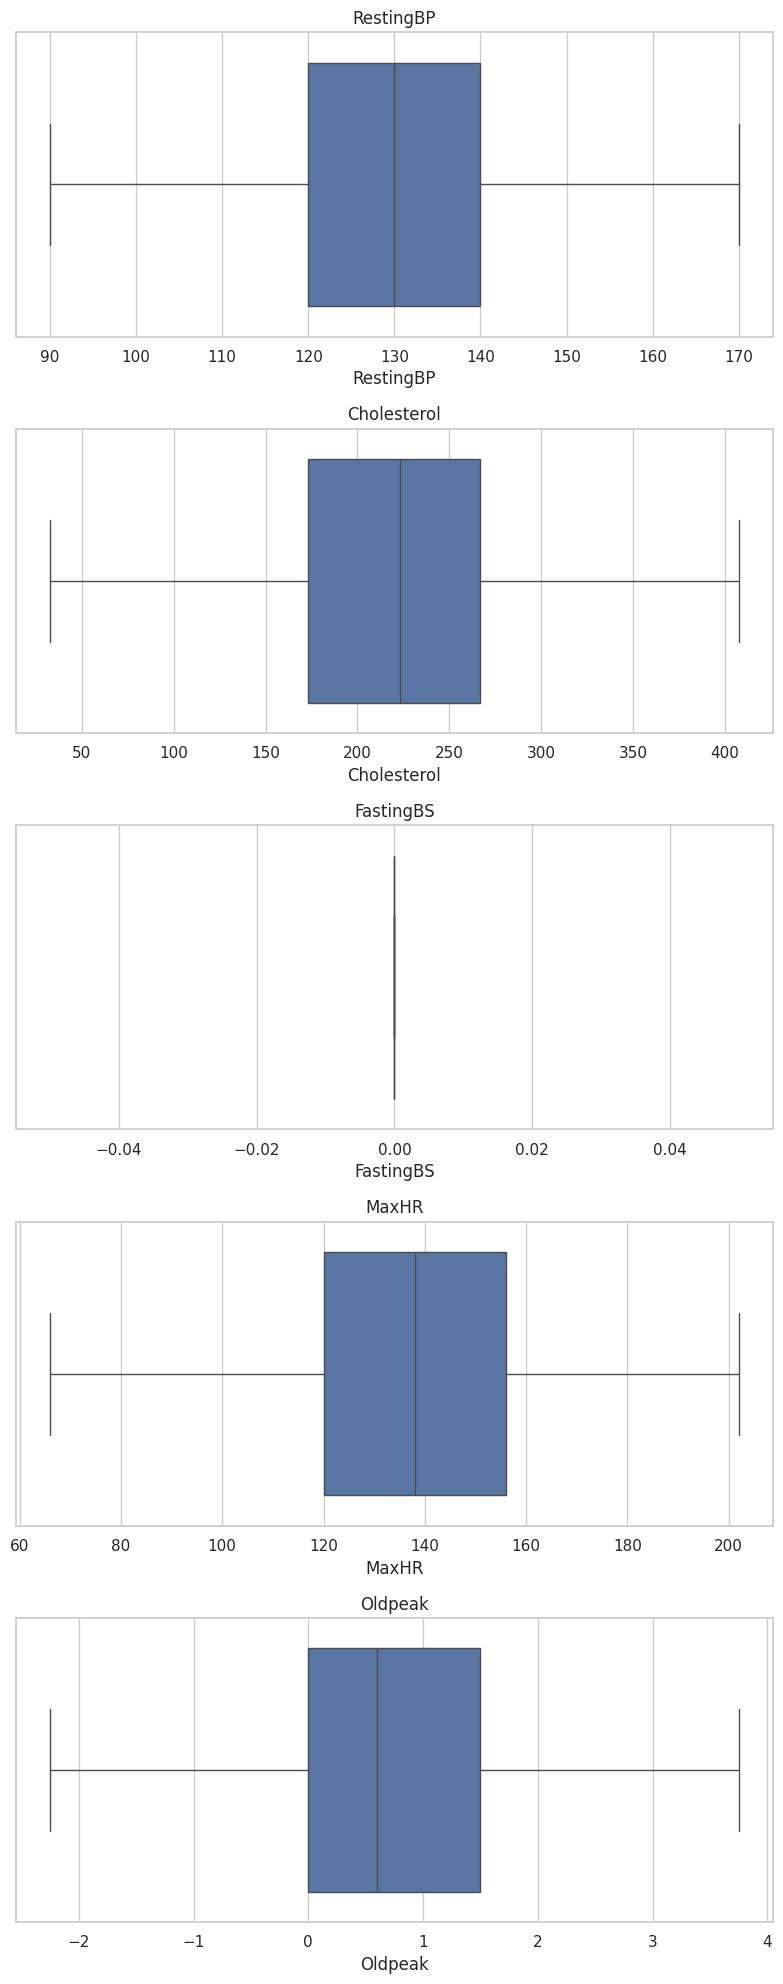

In [49]:
#checking the columns after the outliers treatment
fig, axes = plt.subplots(len(outlier_cols),1, figsize = (8,20))
for i, col in enumerate(outlier_cols):
    sns.boxplot(data = df, x = col, ax = axes[i])
    axes[i].set_title(col)
plt.tight_layout()
plt.show()

In [50]:
#converting categorical columns to numerical columns using One-Hot encoding
categorical_columns = df.select_dtypes(include='object').columns

df = pd.get_dummies(
    df,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

In [51]:
# x and y separation
x = df.drop("HeartDisease", axis = 1)
y = df["HeartDisease"]

In [52]:
#splitting the data into training and testing sets
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 42)
x_train.shape, x_test.shape, y_train.shape, y_test.shape

((734, 15), (184, 15), (734,), (184,))

In [55]:
#To balance the dataset
from imblearn.over_sampling import SMOTE
print("Before Smote:\n",y_train.value_counts())
smote = SMOTE(random_state = 42)
x_train_resampled, y_train_resampled = smote.fit_resample(x_train, y_train)
print("After Smote:\n",y_train_resampled.value_counts())

Before Smote:
 HeartDisease
1    401
0    333
Name: count, dtype: int64
After Smote:
 HeartDisease
0    401
1    401
Name: count, dtype: int64


In [56]:
#Performing the feature scaling
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

There is no null values in the column there is no need to do median imputation

In [63]:
# Scale the resampled training features and test features
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

x_train_resampled_scaled = scaler.fit_transform(x_train_resampled)
x_test_scaled = scaler.transform(x_test_clean)

# Fit logistic regression on the scaled resampled training data
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(solver='lbfgs', max_iter=1000)
model.fit(x_train_resampled_scaled, y_train_resampled)

LogisticRegression(max_iter=1000)

In [64]:
#Training the model to make predictions
y_pred = model.predict(x_test)

In [65]:
#comparing the actual and predicted data
comparison = pd.DataFrame({"Actual": y_test, "Predicted": y_pred})
comparison.head(10)

,Actual,Predicted
668,0,0
30,1,0
377,1,1
535,1,1
807,0,0
793,1,1
363,1,1
583,0,0
165,1,1
483,1,1


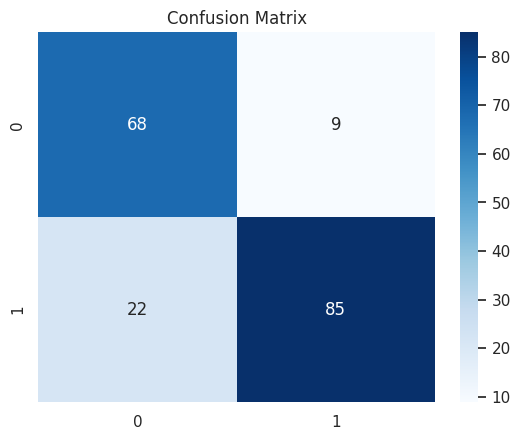

accuracy: 0.8315217391304348
precision: 0.9042553191489362
recall: 0.794392523364486
f1 score: 0.845771144278607
classification report:
               precision    recall  f1-score   support

           0       0.76      0.88      0.81        77
           1       0.90      0.79      0.85       107

    accuracy                           0.83       184
   macro avg       0.83      0.84      0.83       184
weighted avg       0.84      0.83      0.83       184



In [67]:
# Metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label=1)
recall = recall_score(y_test, y_pred, pos_label=1)
f1 = f1_score(y_test, y_pred, pos_label=1)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)
sns.heatmap(conf_matrix, annot = True, fmt = "d", cmap = "Blues")
plt.title("Confusion Matrix")
plt.show()
print("accuracy:", accuracy)
print("precision:", precision)
print("recall:", recall)
print("f1 score:", f1)
print("classification report:\n", class_report)

ROC-AUC: 0.9141886151231944


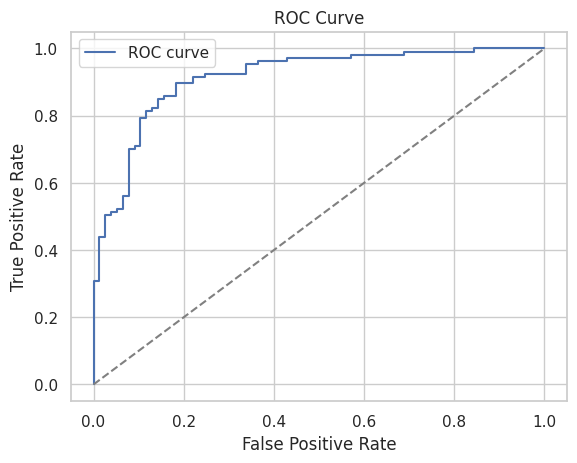

In [69]:
# Import necessary metrics
from sklearn.metrics import roc_auc_score, roc_curve

# Calculate prediction probabilities
y_pred_proba = model.predict_proba(x_test_scaled)[:, 1]

# ROC-AUC score
print("ROC-AUC:", roc_auc_score(y_test, y_pred_proba))

# Plot ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
plt.plot(fpr, tpr, label="ROC curve")
plt.plot([0,1],[0,1],'--', color='gray')  # random guess line
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

True Positives (85) → The model correctly identified 85 patients with heart disease.

True Negatives (68) → The model correctly identified 68 patients without heart disease.

False Positives (9) → Only 9 patients were incorrectly flagged as having heart disease when they didn’t. This shows high precision.

False Negatives (22) → 22 patients with heart disease were missed. This is the main weakness, as recall (sensitivity) is lower.

Accuracy ≈ 83% → Overall, the model is fairly accurate.

Precision ≈ 90% → When the model predicts heart disease, it is right most of the time.

Recall ≈ 79% → The model detects most heart disease cases, but misses about 1 in 5.

Balance → Strong precision but weaker recall means the model is cautious about false alarms but risks missing some true cases.

our model is very good at distinguishing between patients with and without heart disease.

The ROC curve confirms what the confusion matrix suggested: strong precision and good recall, though recall could still be improved.

In medical contexts, you might adjust the classification threshold to prioritize higher recall (catching more true cases), even if it slightly reduces precision.